# Quick start: from a material to a fitted measurement

This notebook simulates one Bragg-edge transmission measurement with four
overlapping pulses per period and analyses it in two ways:

* the **Rietveld fit of the overlapped spectrum**: the nbragg model is passed
  through the known pulse pattern and fitted to the counts, and
* **Wiener deconvolution** as in frame-overlap Bragg-edge imaging (FOBI),
  followed by a fit of the recovered transmission.

The material is described exactly as in nbragg.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import nbragg
import frame_overlap as fo

# the material, as in nbragg: 2 cm of alpha-iron
xs = nbragg.CrossSection(materials={"iron": {"mat": "Fe_sg229_Iron-alpha.ncmat"}})
model = nbragg.TransmissionModel(xs, response="jorgensen_inv", tof_length=9.0, vary_response=False)
model.params["thickness"].set(value=2.0)     # cm
model.params["α0"].set(value=3000.0)         # moderator response (rise), close to a water moderator
model.params["β0"].set(value=50.0)           # moderator response (decay)
sample = fo.Sample(model, free=["thickness", "strain"])

# the instrument: 9 m flight path, 50 ms period, 10 us bins, a thermal moderator
grid = fo.TimeGrid(flight_path=9.0, frequency=20.0, bin_width=10e-6)
beam = fo.OpenBeam.maxwellian(grid, flux=5e6, area=0.03)
hours = 8

## The measurement design

A pulse pattern says when the chopper opens within the period. Here: one
200 µs pulse per period, and four pulses at times chosen so that the intense
thermal part of each spectrum avoids the Bragg edges of the others.

In [2]:
one = fo.Pattern.single(200e-6)
four = fo.Pattern.times([0.0, 11.97e-3, 22.33e-3, 35.48e-3], width=200e-6)
exp1 = fo.Experiment(sample, beam, one, time=hours * 3600)
exp4 = fo.Experiment(sample, beam, four, time=hours * 3600)
print(exp4)
print(exp1.precision())    # Cramer-Rao bound: the best any unbiased analysis can do
print(exp4.precision())
print("time-reduction factor of the four pulses:", exp4.gain())

Experiment(Pattern(4 pulses: starts [0.0, 11.97, 22.33, 35.48] ms, widths [200.0] us), 8 h, Sample(free: thickness=2, strain=0))


   parameter  value     sigma unit  sigma_microstrain
0  thickness    2.0  0.000761   cm                NaN
1     strain    0.0  0.000172    1         172.090732
   parameter  value     sigma unit  sigma_microstrain
0  thickness    2.0  0.000442   cm                NaN
1     strain    0.0  0.000087    1          87.205282
time-reduction factor of the four pulses: {'thickness': 2.966318172485095, 'strain': 3.8942997638651957}


The time-reduction factor *R* is the factor by which the measurement with
one pulse per period would have to be longer to reach the same precision.

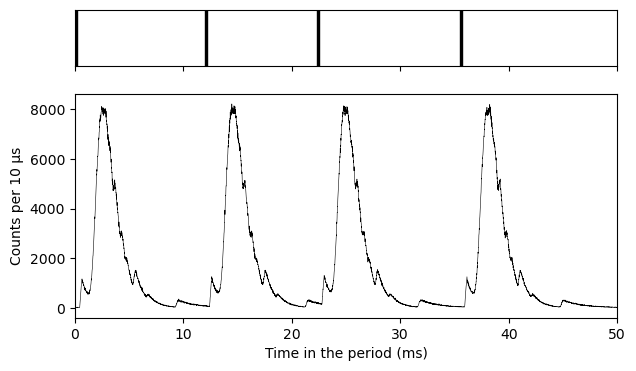

In [3]:
data = exp4.simulate(seed=1)
fig, (a0, a1) = plt.subplots(2, 1, figsize=(7, 4), sharex=True, gridspec_kw=dict(height_ratios=[1, 4]))
four.plot(a0, period=grid.period)
data.plot(a1)
a0.set_xlabel("")
plt.show()

## Rietveld fit of the overlapped spectrum

The fit starts away from the truth (here 1.9 cm and 300 microstrain);
the greys show the contribution of each pulse to the fitted counts.

[[Rietveld fit]]
    converged after 12 evaluations
    deviance per bin = 0.981 (5000 bins with counts)
[[Parameters]]
    thickness         1.99921 +/- 0.000442   (truth 2)
    strain        1.28656e-05 +/- 8.73e-05  = 12.9 +/- 87.3 microstrain   (truth 0)


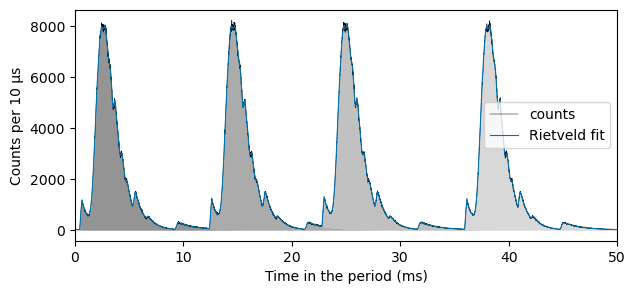

In [4]:
rietveld = fo.RietveldFit(window=(1.0, 5.0)).fit(data, sample, theta0=[1.9, 3e-4])
print(rietveld.fit_report())
fig, ax = plt.subplots(figsize=(7, 3))
rietveld.plot(ax)
plt.show()

The fit also recovers the transmission spectrum: the counts of each bin
are divided between the pulses in proportion to their fitted contributions,
as Rietveld programs divide the counts of overlapping reflections.

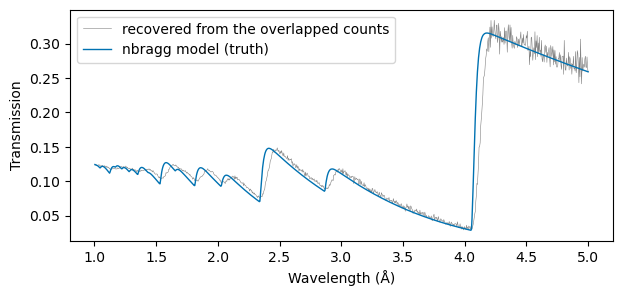

In [5]:
lam, T, dT = rietveld.transmission()
sel = (lam > 1) & (lam < 5)
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(lam[sel], T[sel], color="0.5", lw=0.4, label="recovered from the overlapped counts")
ax.plot(lam[sel], sample.transmission(grid)[sel], color="#0072B2", lw=1, label="nbragg model (truth)")
ax.set_xlabel("Wavelength (Å)"); ax.set_ylabel("Transmission"); ax.legend()
plt.show()

## Wiener deconvolution (FOBI)

[[Wiener deconvolution]]
    converged after 7 evaluations
    chi2 per bin = 1.237 (910 bins with counts)
[[Parameters]]
    thickness         1.99982 +/- 0.00205   (truth 2)
    strain        3.94631e-05 +/- 0.00044  = 39.5 +/- 440.4 microstrain   (truth 0)
    note: errors include the correlations created by the deconvolution (sandwich estimate)


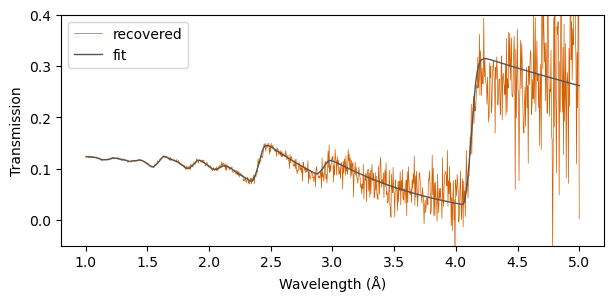

In [6]:
wiener = fo.WienerFit(noise_power=1e-3).fit(data, sample, theta0=[1.9, 3e-4])
print(wiener.fit_report())
fig, ax = plt.subplots(figsize=(7, 3))
wiener.plot(ax)
ax.set_ylim(-0.05, 0.4)
plt.show()

## Comparison

Both analyses use the same counts. The Rietveld fit reaches the Cramér–Rao
bound; the deconvolution followed by a fit with independent bins does not.

In [7]:
import pandas as pd
bound = exp4.precision().set_index("parameter").sigma
pd.DataFrame({"Cramer-Rao bound": bound,
              "Rietveld fit": pd.Series(rietveld.errors),
              "Wiener deconvolution": pd.Series(wiener.errors)})

,Cramer-Rao bound,Rietveld fit,Wiener deconvolution
thickness,0.000442,0.000442,0.002055
strain,0.000087,0.000087,0.000440


## Check with a Monte Carlo

The errors above come from the curvature of the likelihood. A Monte Carlo of
simulated measurements, each fitted from displaced starting values, checks
that the scatter of the results matches them and that the fit is unbiased.
Use more draws (and ``workers``) for a real check.

In [8]:
est, mc = fo.monte_carlo(exp4, fo.RietveldFit(), n=24, seed=0, workers=4)
mc.round(6)

,parameter,truth,mean,bias,std,bound,std/bound,bias/std,n_ok
0,thickness,2.0,1.999895,-0.000105,0.000382,0.000442,0.864744,-0.273563,24
1,strain,0.0,0.000002,0.000002,0.000112,0.000087,1.279815,0.019360,24
